In [2]:

import pandas as pd

df = pd.read_csv("heart_failure_clinical_records_dataset.csv")

df.head()


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [3]:

print("Dataset shape:", df.shape)

df.info()

df.describe().T


Dataset shape: (299, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 3

,count,mean,std,min,25%,50%,75%,max
age,299.0,60.833893,11.894809,40.0,51.0,60.0,70.0,95.0
anaemia,299.0,0.431438,0.496107,0.0,0.0,0.0,1.0,1.0
creatinine_phosphokinase,299.0,581.839465,970.287881,23.0,116.5,250.0,582.0,7861.0
diabetes,299.0,0.418060,0.494067,0.0,0.0,0.0,1.0,1.0
ejection_fraction,299.0,38.083612,11.834841,14.0,30.0,38.0,45.0,80.0
high_blood_pressure,299.0,0.351171,0.478136,0.0,0.0,0.0,1.0,1.0
platelets,299.0,263358.029264,97804.236869,25100.0,212500.0,262000.0,303500.0,850000.0
serum_creatinine,299.0,1.393880,1.034510,0.5,0.9,1.1,1.4,9.4
serum_sodium,299.0,136.625418,4.412477,113.0,134.0,137.0,140.0,148.0
sex,299.0,0.648829,0.478136,0.0,0.0,1.0,1.0,1.0


In [4]:

missing = df.isnull().sum()

print("Missing values per column:")
print(missing)

print("Total missing values:", missing.sum())
print("Missing percentage:",
      df.isnull().sum().sum() / df.size * 100)


Missing values per column:
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64
Total missing values: 0
Missing percentage: 0.0


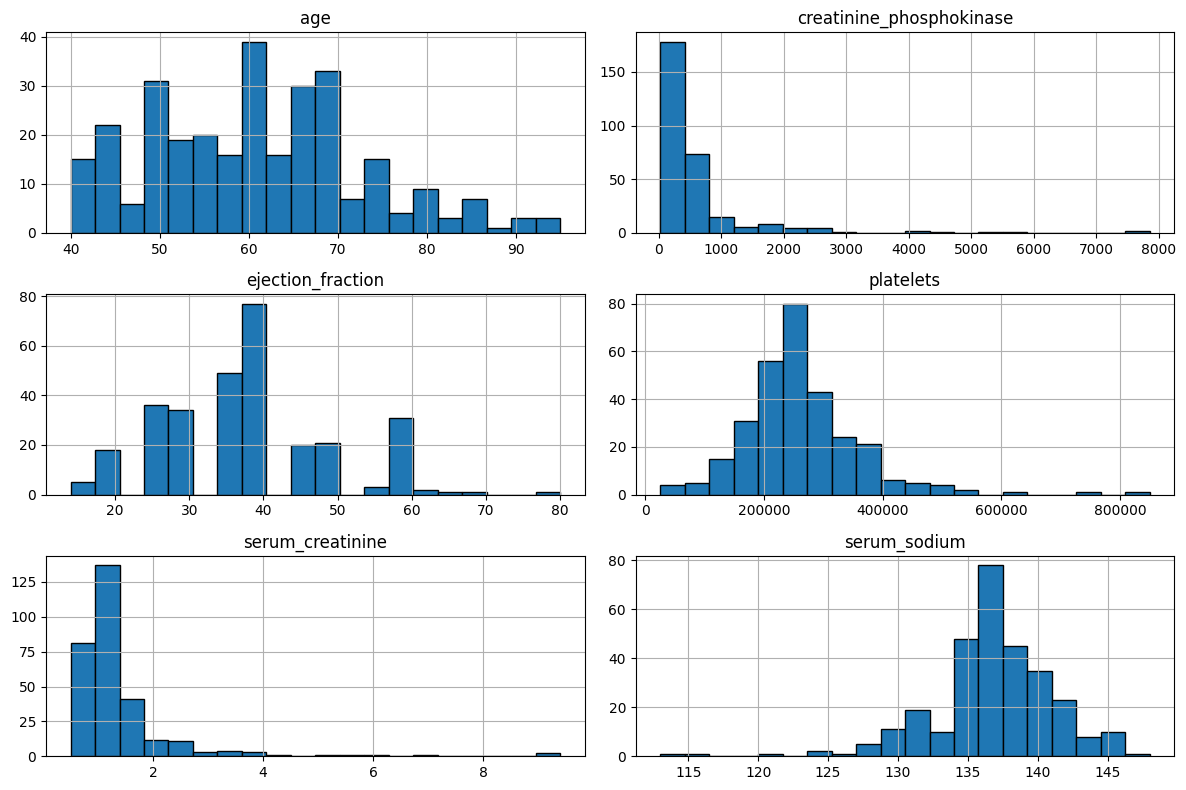

In [5]:

import matplotlib.pyplot as plt

continuous_features = [
    "age",
    "creatinine_phosphokinase",
    "ejection_fraction",
    "platelets",
    "serum_creatinine",
    "serum_sodium"
]

df[continuous_features].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.tight_layout()
plt.show()


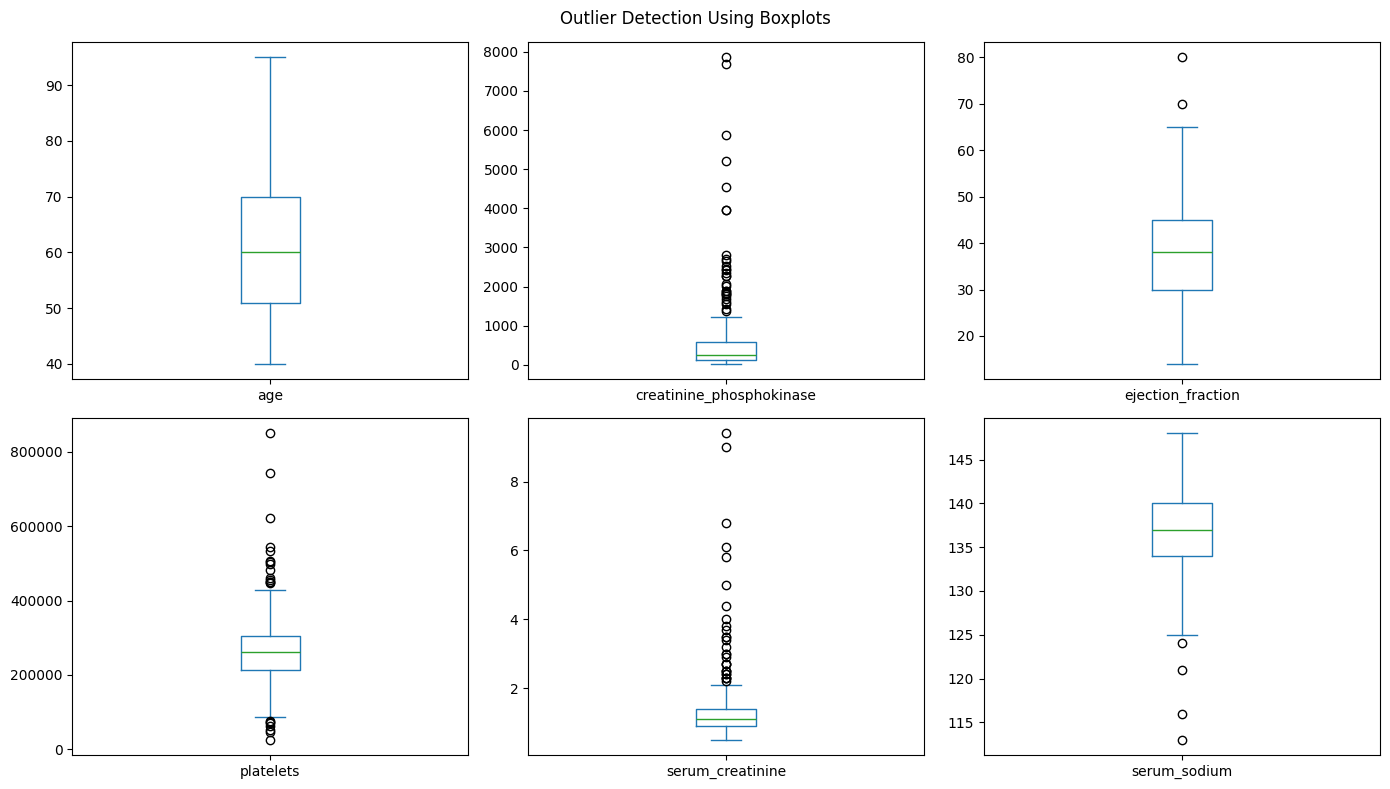

In [6]:

import matplotlib.pyplot as plt

continuous_features = [
    "age",
    "creatinine_phosphokinase",
    "ejection_fraction",
    "platelets",
    "serum_creatinine",
    "serum_sodium"
]

df[continuous_features].plot(
    kind="box",
    subplots=True,
    layout=(2, 3),
    figsize=(14, 8),
    sharey=False
)

plt.suptitle("Outlier Detection Using Boxplots")
plt.tight_layout()
plt.show()


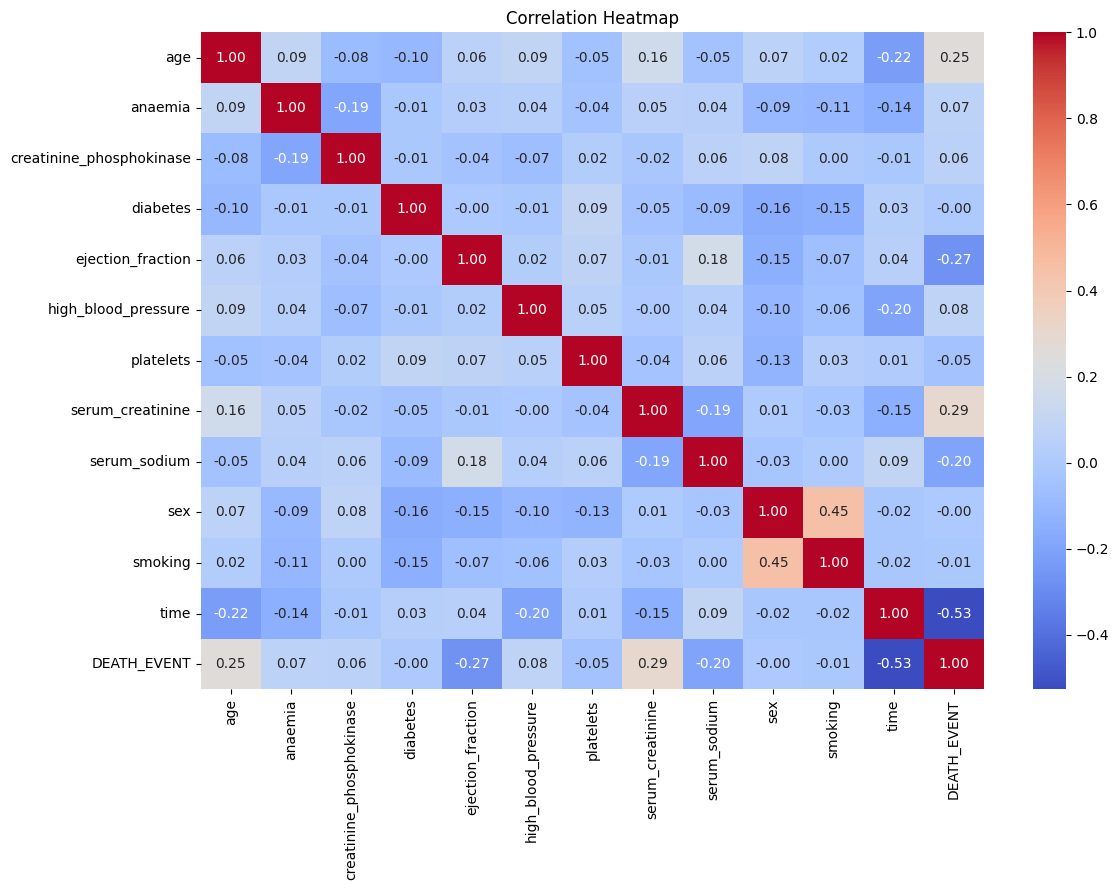

In [7]:

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 9))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


In [8]:

%pip install lifelines


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


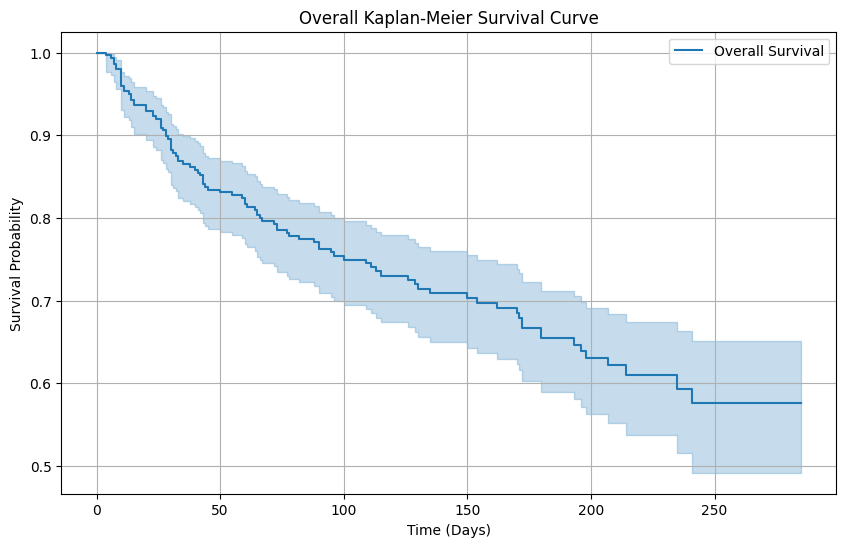

In [9]:

from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt

kmf = KaplanMeierFitter()

kmf.fit(
    durations=df["time"],
    event_observed=df["DEATH_EVENT"],
    label="Overall Survival"
)

plt.figure(figsize=(10, 6))

kmf.plot_survival_function()

plt.title("Overall Kaplan-Meier Survival Curve")
plt.xlabel("Time (Days)")
plt.ylabel("Survival Probability")
plt.grid(True)
plt.show()


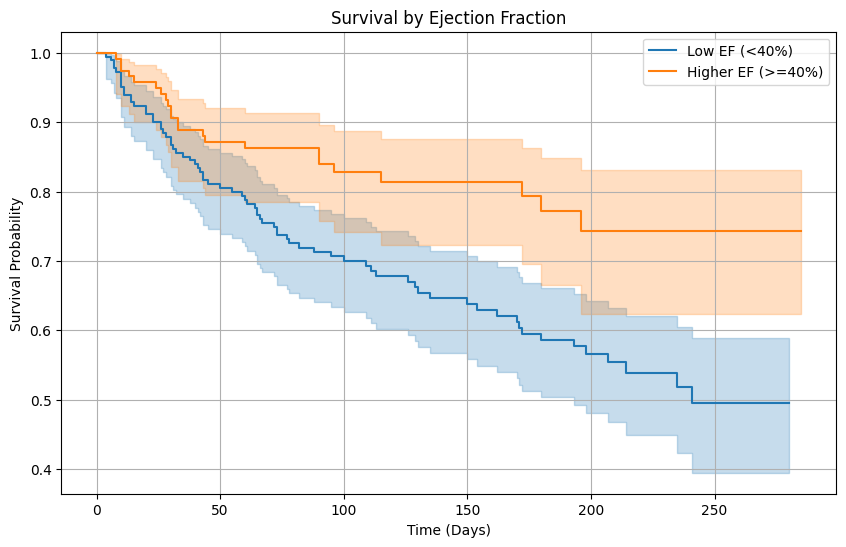

In [10]:

low_ef = df[df["ejection_fraction"] < 40]
higher_ef = df[df["ejection_fraction"] >= 40]

kmf_low = KaplanMeierFitter()
kmf_higher = KaplanMeierFitter()

plt.figure(figsize=(10, 6))

kmf_low.fit(
    low_ef["time"],
    event_observed=low_ef["DEATH_EVENT"],
    label="Low EF (<40%)"
)

kmf_low.plot_survival_function()

kmf_higher.fit(
    higher_ef["time"],
    event_observed=higher_ef["DEATH_EVENT"],
    label="Higher EF (>=40%)"
)

kmf_higher.plot_survival_function()

plt.title("Survival by Ejection Fraction")
plt.xlabel("Time (Days)")
plt.ylabel("Survival Probability")
plt.grid(True)
plt.show()


In [11]:

selected_features = [
    "age",
    "anaemia",
    "creatinine_phosphokinase",
    "diabetes",
    "ejection_fraction",
    "high_blood_pressure",
    "platelets",
    "serum_creatinine",
    "serum_sodium",
    "sex"
]

print("Number of selected features:",
      len(selected_features))

print("Selected features:")
print(selected_features)


Number of selected features: 10
Selected features:
['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex']


In [12]:

cleaned_df = df[
    selected_features + ["time", "DEATH_EVENT"]
].copy()

print("Cleaned dataset shape:", cleaned_df.shape)

print("Missing values:",
      cleaned_df.isnull().sum().sum())

cleaned_df.head()


Cleaned dataset shape: (299, 12)
Missing values: 0


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,8,1


In [20]:

cleaned_df.to_csv(
    "heart_failure_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [21]:

from sklearn.model_selection import RepeatedStratifiedKFold
import numpy as np

print("Cross-validation libraries imported!")


Cross-validation libraries imported!


In [22]:

X = cleaned_df[selected_features]
y = cleaned_df["DEATH_EVENT"]

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=42
)

folds = list(cv.split(X, y))

print("Total folds:", len(folds))

for i, (train_idx, test_idx) in enumerate(folds, 1):
    print(
        "Fold", i,
        "Training:", len(train_idx),
        "Testing:", len(test_idx)
    )


Total folds: 15
Fold 1 Training: 239 Testing: 60
Fold 2 Training: 239 Testing: 60
Fold 3 Training: 239 Testing: 60
Fold 4 Training: 239 Testing: 60
Fold 5 Training: 240 Testing: 59
Fold 6 Training: 239 Testing: 60
Fold 7 Training: 239 Testing: 60
Fold 8 Training: 239 Testing: 60
Fold 9 Training: 239 Testing: 60
Fold 10 Training: 240 Testing: 59
Fold 11 Training: 239 Testing: 60
Fold 12 Training: 239 Testing: 60
Fold 13 Training: 239 Testing: 60
Fold 14 Training: 239 Testing: 60
Fold 15 Training: 240 Testing: 59


In [23]:

import json

fold_data = []

for i, (train_idx, test_idx) in enumerate(folds, 1):
    fold_data.append({
        "repeat": (i - 1) // 5 + 1,
        "fold": (i - 1) % 5 + 1,
        "train_indices": train_idx.tolist(),
        "test_indices": test_idx.tolist()
    })

with open("csv_folds.json", "w") as f:
    json.dump(fold_data, f, indent=2)

print("Cross-validation folds saved successfully!")


Cross-validation folds saved successfully!


In [24]:

import pandas as pd
import json

# Load cleaned dataset
df_clean = pd.read_csv("heart_failure_cleaned.csv")

# Load cross-validation folds
with open("csv_folds.json", "r") as f:
    folds_check = json.load(f)

# Check cleaned dataset
print("Dataset shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())

assert df_clean.shape == (299, 12)
assert df_clean.isnull().sum().sum() == 0

# Check all cross-validation folds
print("Total folds:", len(folds_check))
assert len(folds_check) == 15

for i, fold in enumerate(folds_check, 1):
    train = fold["train_indices"]
    test = fold["test_indices"]

    assert len(train) == len(set(train))
    assert len(test) == len(set(test))
    assert set(train).isdisjoint(set(test))
    assert set(train) | set(test) == set(range(299))

    print(f"Fold {i}: {len(train)} train, {len(test)} test")

print("All checks passed successfully!")


Dataset shape: (299, 12)
Missing values: 0
Total folds: 15
Fold 1: 239 train, 60 test
Fold 2: 239 train, 60 test
Fold 3: 239 train, 60 test
Fold 4: 239 train, 60 test
Fold 5: 240 train, 59 test
Fold 6: 239 train, 60 test
Fold 7: 239 train, 60 test
Fold 8: 239 train, 60 test
Fold 9: 239 train, 60 test
Fold 10: 240 train, 59 test
Fold 11: 239 train, 60 test
Fold 12: 239 train, 60 test
Fold 13: 239 train, 60 test
Fold 14: 239 train, 60 test
Fold 15: 240 train, 59 test
All checks passed successfully!
